# Algoritmo de Prim

Obtiene el árbol de expansión mínima de un grafo no dirigido ponderado haciéndolo crecer desde un nodo: en cada paso añade la arista más barata que une un nodo del árbol con uno de fuera. Cada nodo $v$ de fuera tiene como coste $\text{clave}(v) = \min_{u \in \text{árbol}} w(u, v)$. Con `heapq` cuesta $O(E \log V)$; con una matriz de adyacencia y sin cola, $O(V^2)$, que es mejor en grafos densos ($E \approx V^2$).

Los grafos se representan como `nodo → {vecino: peso}`, igual que en Dijkstra.

## 1. Árbol de expansión mínima con `heapq`

Calcular el árbol de expansión mínima de la misma red de ciudades que en Kruskal, empezando en Madrid, y su coste total.

In [1]:
import heapq

nodos = ["Madrid", "Toledo", "Segovia", "Ávila", "Cuenca", "Guadalajara"]
aristas = [
    ("Madrid", "Toledo", 72), ("Madrid", "Segovia", 91), ("Madrid", "Ávila", 107),
    ("Madrid", "Cuenca", 167), ("Madrid", "Guadalajara", 60), ("Segovia", "Ávila", 67),
    ("Toledo", "Cuenca", 185), ("Guadalajara", "Cuenca", 135), ("Toledo", "Ávila", 137),
]

def grafo_no_dirigido(aristas):
    grafo = {}
    for u, v, w in aristas:
        grafo.setdefault(u, {})[v] = w
        grafo.setdefault(v, {})[u] = w
    return grafo

def prim(grafo, inicio):
    en_arbol, arbol = {inicio}, []
    cola = [(w, inicio, v) for v, w in grafo[inicio].items()]
    heapq.heapify(cola)
    while cola and len(en_arbol) < len(grafo):
        w, u, v = heapq.heappop(cola)
        # ya se unió por una arista más barata
        if v in en_arbol:
            continue
        en_arbol.add(v)
        arbol.append((u, v, w))
        for x, wx in grafo[v].items():
            if x not in en_arbol:
                heapq.heappush(cola, (wx, v, x))
    return arbol

grafo = grafo_no_dirigido(aristas)
arbol = prim(grafo, "Madrid")
for arista in arbol:
    print(arista)
print("Coste total:", sum(w for _, _, w in arbol))

('Madrid', 'Guadalajara', 60)
('Madrid', 'Toledo', 72)
('Madrid', 'Segovia', 91)
('Segovia', 'Ávila', 67)
('Guadalajara', 'Cuenca', 135)
Coste total: 425


## 2. Comprobación contra Kruskal

Reimplementar un Kruskal mínimo y comprobar en grafos conexos aleatorios que ambos dan el mismo peso total (los árboles pueden ser distintos si hay pesos repetidos). En grafos pequeños, comprobarlo también contra fuerza bruta probando todos los subconjuntos de $V - 1$ aristas.

In [2]:
import random
from itertools import combinations

def kruskal(nodos, aristas):
    padre = {n: n for n in nodos}

    def raiz(x):
        while padre[x] != x:
            x = padre[x]
        return x

    arbol = []
    for u, v, w in sorted(aristas, key=lambda a: a[2]):
        ru, rv = raiz(u), raiz(v)
        if ru != rv:
            padre[ru] = rv
            arbol.append((u, v, w))
    return arbol

def peso(arbol):
    return sum(w for _, _, w in arbol)

def es_conexo(nodos, aristas):
    g = grafo_no_dirigido(aristas)
    vistos, pila = {nodos[0]}, [nodos[0]]
    while pila:
        for v in g.get(pila.pop(), {}):
            if v not in vistos:
                vistos.add(v)
                pila.append(v)
    return len(vistos) == len(nodos)

def fuerza_bruta(nodos, aristas):
    return min(peso(c) for c in combinations(aristas, len(nodos) - 1) if es_conexo(nodos, c))

def grafo_aleatorio(n, p, peso_max):
    # un camino por todos los nodos asegura que es conexo
    orden = random.sample(range(n), n)
    pares = {tuple(sorted(orden[i:i + 2])) for i in range(n - 1)}
    pares |= {(u, v) for u, v in combinations(range(n), 2) if random.random() < p}
    return [(u, v, random.randint(1, peso_max)) for u, v in sorted(pares)]

print("Prim:", peso(arbol), " Kruskal:", peso(kruskal(nodos, aristas)), " fuerza bruta:", fuerza_bruta(nodos, aristas))

random.seed(2)
for _ in range(300):
    n = random.randint(2, 7)
    ar = grafo_aleatorio(n, 0.4, 10)
    assert peso(prim(grafo_no_dirigido(ar), 0)) == peso(kruskal(range(n), ar)) == fuerza_bruta(list(range(n)), ar)
for _ in range(50):
    n = random.randint(2, 200)
    ar = grafo_aleatorio(n, 0.1, 1000)
    arbol_prim = prim(grafo_no_dirigido(ar), 0)
    assert len(arbol_prim) == n - 1 and peso(arbol_prim) == peso(kruskal(range(n), ar))

Prim: 425  Kruskal: 425  fuerza bruta: 425


## 3. Versión con matriz, $O(V^2)$

Con la matriz de adyacencia (`inf` donde no hay arista) basta un vector `clave` con el coste más barato para unir cada nodo al árbol: en cada paso se elige el de menor clave recorriendo el vector y se actualizan las claves con su fila. Comprobarla contra la versión con `heapq`.

In [3]:
from math import inf

def prim_matriz(matriz):
    n = len(matriz)
    clave, padre, en_arbol = [inf] * n, [None] * n, [False] * n
    clave[0] = 0
    arbol = []
    for _ in range(n):
        u = min((i for i in range(n) if not en_arbol[i]), key=lambda i: clave[i])
        if clave[u] == inf:
            break  # no es conexo
        en_arbol[u] = True
        if padre[u] is not None:
            arbol.append((padre[u], u, matriz[padre[u]][u]))
        for v in range(n):
            if not en_arbol[v] and matriz[u][v] < clave[v]:
                clave[v], padre[v] = matriz[u][v], u
    return arbol

def a_matriz(n, aristas):
    matriz = [[inf] * n for _ in range(n)]
    for u, v, w in aristas:
        matriz[u][v] = matriz[v][u] = w
    return matriz

indice = {c: i for i, c in enumerate(nodos)}
arbol_matriz = prim_matriz(a_matriz(len(nodos), [(indice[u], indice[v], w) for u, v, w in aristas]))
print([(nodos[u], nodos[v], w) for u, v, w in arbol_matriz], peso(arbol_matriz))

random.seed(3)
for _ in range(200):
    n = random.randint(2, 40)
    ar = grafo_aleatorio(n, random.random(), 50)
    assert peso(prim_matriz(a_matriz(n, ar))) == peso(prim(grafo_no_dirigido(ar), 0))

[('Madrid', 'Guadalajara', 60), ('Madrid', 'Toledo', 72), ('Madrid', 'Segovia', 91), ('Segovia', 'Ávila', 67), ('Guadalajara', 'Cuenca', 135)] 425


## 4. Dibujar el grafo y el árbol

Dibujar con `matplotlib` la red de ciudades (con coordenadas aproximadas) y los pesos de las aristas, marcando en rojo las del árbol de expansión mínima.

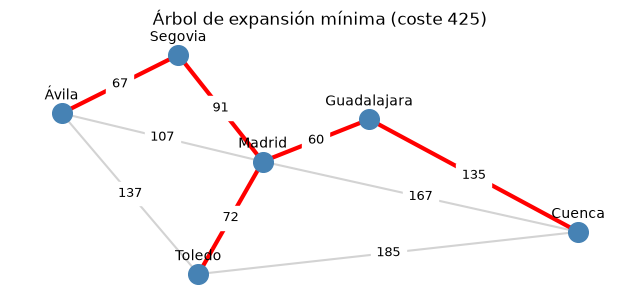

In [4]:
import matplotlib.pyplot as plt

posiciones = {"Madrid": (-3.70, 40.42), "Toledo": (-4.02, 39.86), "Segovia": (-4.12, 40.95),
              "Ávila": (-4.70, 40.66), "Cuenca": (-2.13, 40.07), "Guadalajara": (-3.17, 40.63)}
del_arbol = {frozenset((u, v)) for u, v, _ in arbol}

fig, eje = plt.subplots(figsize=(8, 5))
for u, v, w in aristas:
    (x1, y1), (x2, y2) = posiciones[u], posiciones[v]
    dentro = frozenset((u, v)) in del_arbol
    eje.plot([x1, x2], [y1, y2], color="red" if dentro else "lightgray", linewidth=3 if dentro else 1.5, zorder=1)
    eje.text((x1 + x2) / 2, (y1 + y2) / 2, w, ha="center", va="center", fontsize=9, backgroundcolor="white")
for nombre, (x, y) in posiciones.items():
    eje.scatter(x, y, s=200, color="steelblue", zorder=2)
    eje.annotate(nombre, (x, y), xytext=(0, 10), textcoords="offset points", ha="center")
eje.set_title(f"Árbol de expansión mínima (coste {peso(arbol)})")
eje.margins(0.1)
eje.set_aspect("equal")
eje.axis("off")
plt.show()

## 5. Red de cable mínima entre puntos

Unir 40 puntos aleatorios del plano con la menor longitud total de cable. El grafo es completo (distancia euclídea entre cada par), justo el caso en que conviene la versión con matriz. Comprobar contra Kruskal y dibujar los puntos y el árbol.

39 cables, longitud total 4.063


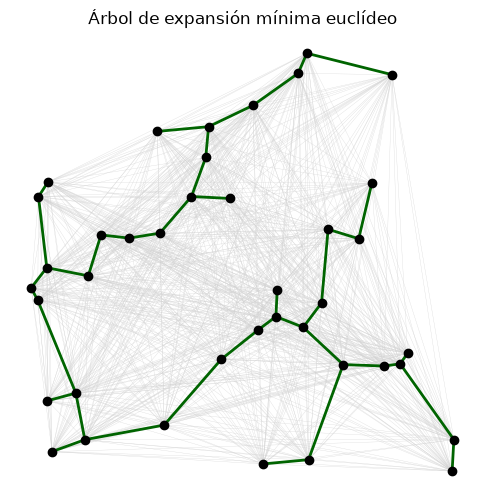

In [5]:
from math import dist, isclose

random.seed(7)
puntos = [(random.random(), random.random()) for _ in range(40)]
matriz = [[dist(p, q) for q in puntos] for p in puntos]
red = prim_matriz(matriz)
pares = [(i, j, matriz[i][j]) for i, j in combinations(range(len(puntos)), 2)]
assert isclose(peso(red), peso(kruskal(range(len(puntos)), pares)))
print(len(red), "cables, longitud total", round(peso(red), 3))

fig, eje = plt.subplots(figsize=(6, 6))
for i, j in combinations(range(len(puntos)), 2):
    eje.plot(*zip(puntos[i], puntos[j]), color="lightgray", linewidth=0.2, zorder=1)
for u, v, _ in red:
    eje.plot(*zip(puntos[u], puntos[v]), color="darkgreen", linewidth=2, zorder=2)
eje.scatter(*zip(*puntos), color="black", zorder=3)
eje.set_title("Árbol de expansión mínima euclídeo")
eje.set_aspect("equal")
eje.axis("off")
plt.show()